# Multi-Fidelity Method Comparison: Meng Discontinuous

Example is based on the composite NN test case that presents a 1D test case with a discontinuity in the center

In [2]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging, mfkans, kriging
import multi_fidelity_functions

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Introduce the example function

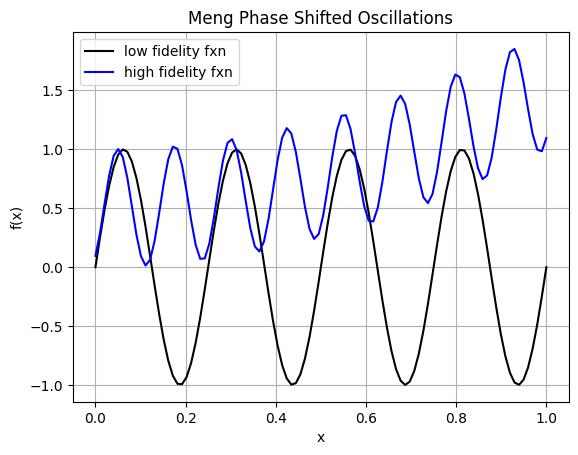

In [3]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.MengPhaseShift()
mf_example.plot_functions(name=mf_example.name)
plt.legend()
plt.grid()
plt.show()

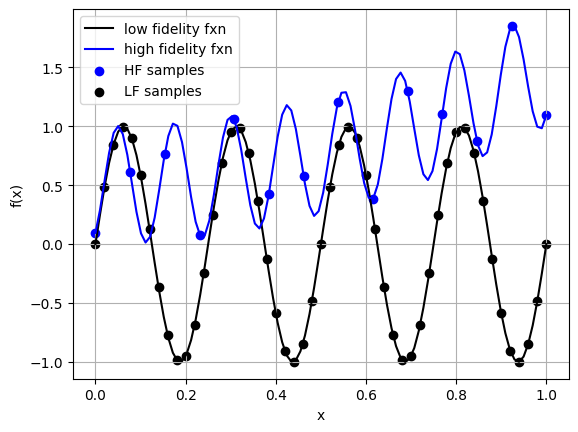

In [4]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 51  # number of low fidelity points
n_hf = 14  # number of high fidelity points
n_test = 100  # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin, xmax, n_lf, dtype=np.float32).reshape(-1, 1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin, xmax, n_hf, dtype=np.float32).reshape(-1, 1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin, xmax, n_test, dtype=np.float32).reshape(-1, 1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name=plot_name)

plt.figure(plot_name)
plt.title("")
plt.scatter(X_hf, y_hf, color="blue", label="HF samples", marker="o")
plt.scatter(X_lf, y_lf, color="black", label="LF samples", marker="o")
plt.legend()
plt.grid()
plt.show()

## Multi-Fidelity Neural Network Fit

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

In [21]:
mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf,
    y_lf=y_lf,
    X_lf_test=X_test,
    y_lf_test=y_lf_test,
    X_hf=X_hf,
    y_hf=y_hf,
    X_hf_test=X_test,
    y_hf_test=y_hf_test,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[10, 10],
    epochs_lf=500,
    epochs_mf=12000,
    lr_lf=0.01,
    wd_lf=0.000001,
    lr_mf=0.0005,
    wd_mf=0.01,
)

Epoch: 0   || Train Error: 0.009494154714047909 || Test Error: 0.005030734930187464

Epoch: 1   || Train Error: 0.009345249272882938 || Test Error: 0.004785803146660328

Epoch: 2   || Train Error: 0.009303772822022438 || Test Error: 0.004706934560090303

Epoch: 3   || Train Error: 0.009291755966842175 || Test Error: 0.004677908960729837

Epoch: 4   || Train Error: 0.009287683293223381 || Test Error: 0.004665615037083626

Epoch: 5   || Train Error: 0.009285222738981247 || Test Error: 0.0046584527008235455

Epoch: 6   || Train Error: 0.009259969927370548 || Test Error: 0.004697051830589771

Epoch: 7   || Train Error: 0.009254232048988342 || Test Error: 0.004719050135463476

Epoch: 8   || Train Error: 0.009251412935554981 || Test Error: 0.004730148706585169

Epoch: 9   || Train Error: 0.009246254339814186 || Test Error: 0.004737642593681812

Epoch: 10   || Train Error: 0.009198992513120174 || Test Error: 0.004548443015664816

Epoch: 11   || Train Error: 0.00899744126945734 || Test Error: 

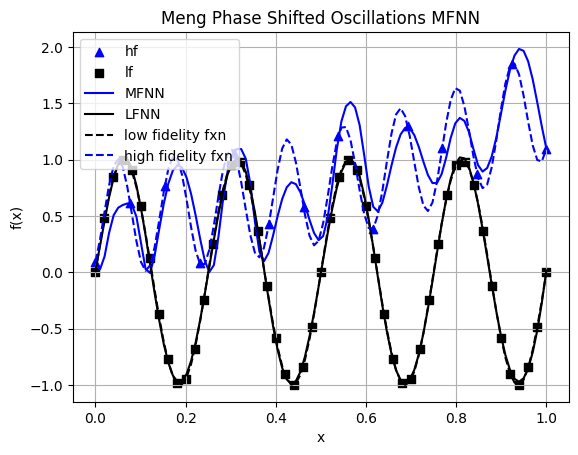

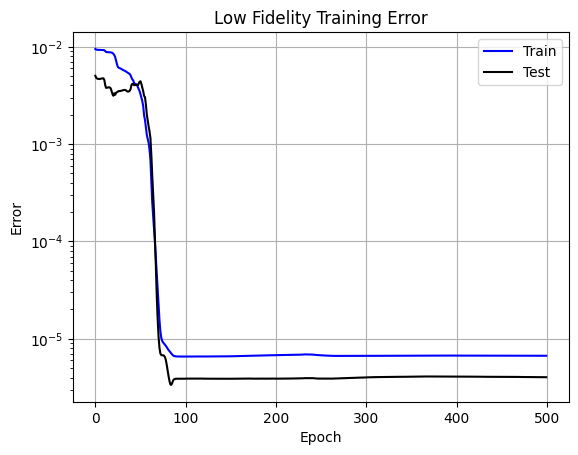

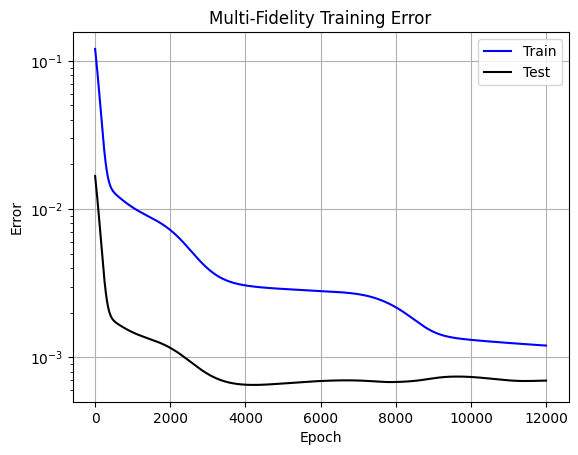

In [38]:
# Plot the results
plot_name = mf_example.name + " MFNN"

ax = mfnn_model.plot_data(plot_name)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MFNN",
    linestyle="solid",
    ax=ax,
)
ax = mfnn_model.low_fidelity_nn.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="black",
    label="LFNN",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

## Co-Kriging Function Fit

Utilizes the Co-Kriging function fit outlined in the Forrester 2007 paper.

In [23]:
cokriging_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf)
kriging_model = kriging.Kriging(X_hf, y_hf)

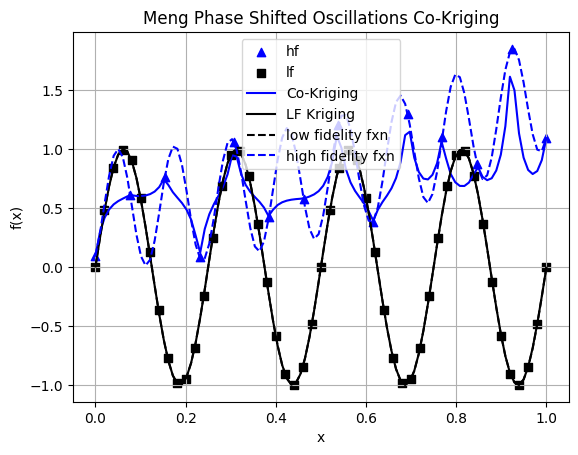

In [24]:
# Plot the results
plot_name = mf_example.name + " Co-Kriging"

ax = cokriging_model.plot_data(plot_name)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="Co-Kriging",
    linestyle="solid",
    ax=ax,
)
ax = cokriging_model.kriging_lf.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF Kriging",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### MFKAN Model
Sets up a MFKAN model for a 1D dataset

In [74]:
# MFKAN Model for forrester mf example
mfkan_model = mfkans.MFKANModel(
    x_lf=X_lf,
    y_lf=y_lf,
    x_lf_test=X_test,
    y_lf_test=y_lf_test,
    x_hf=X_hf,
    y_hf=y_hf,
    x_hf_test=X_test,
    y_hf_test=y_hf_test,
    spline_order_lf=3,
    spline_order_mf=2,
    hidden_layers_lf=[],
    hidden_layers_mf=[5],
    grid_lf=[10, 12],
    grid_mf=[2,3,5],
    opt_lf="LBFGS",
    opt_mf="LBFGS",
    n_iter_lf=20,
    n_iter_mf=100,
    lr_lf=0.1,
    lr_mf=0.001,
)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 1.06e-01 | test_loss: 1.07e-01 | reg: 3.41e+00 | : 100%|█| 20/20 [00:00<00:00, 20.94it


saving model version 0.1
saving model version 0.2


| train_loss: 4.52e-02 | test_loss: 4.54e-02 | reg: 3.42e+00 | : 100%|█| 20/20 [00:01<00:00, 19.09it


saving model version 0.3
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 6.65e-05 | test_loss: 4.35e-01 | reg: 1.79e+01 | : 100%|█| 100/100 [00:11<00:00,  8.89


saving model version 0.1
saving model version 0.2
Does it make it here?


| train_loss: 7.30e-05 | test_loss: 4.61e-01 | reg: 1.77e+01 | : 100%|█| 100/100 [00:09<00:00, 10.81


saving model version 0.3
saving model version 0.4
Does it make it here?


| train_loss: 2.57e-05 | test_loss: 5.42e-01 | reg: 1.78e+01 | : 100%|█| 100/100 [00:07<00:00, 12.62

saving model version 0.5


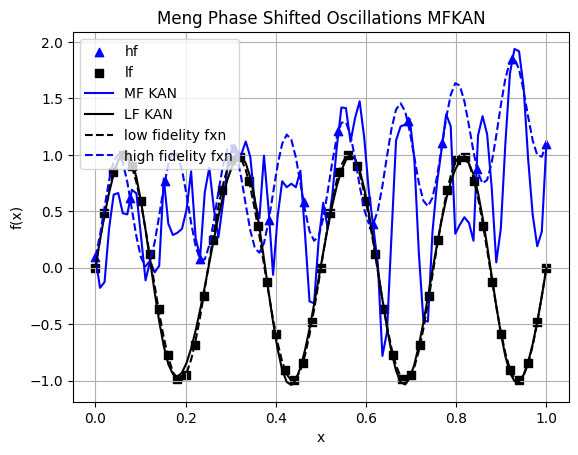

In [75]:
# Plot the results
plot_name = mf_example.name + " MFKAN"

ax = mfkan_model.plot_data(plot_name)
ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="solid",
    ax=ax,
)
ax = mfkan_model.lf_kan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF KAN",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### Method Comparison

Compare the three different methods for their ability to fit the high fidelity function.

In [ ]:
# Set figure size for plots
fig = plt.figure(figsize=(12,9))

# Plot the models and sample data
ax = fig.add_subplot(221)

plot_name = ""

ax = mf_example.plot_functions(name=plot_name, ax=ax)

ax.set_title(plot_name)
ax.scatter(X_hf, y_hf, color="blue", label="HF samples", marker="o")
ax.scatter(X_lf, y_lf, color="black", label="LF samples", marker="o")
ax.grid()
ax.legend()

plot_name = ""

# Plot the model fits
ax = fig.add_subplot(222)

ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
    ax=ax
)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax = kriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="tab:purple",
    label="Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mf_example.plot_high_fidelity(
    name=plot_name, linestyle="solid", color="black", ax=ax
)
ax.grid()
ax.legend()

# Plot the error comparison
ax = fig.add_subplot(223)
plot_name = ""

ax = mfkan_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
    ax=ax
)
ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax.grid()
ax.legend()


# Plot the error comparison
ax = fig.add_subplot(224)
plot_name = ""
names = ["MF KAN", "Co-Kriging", "MFNN"]
print(mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity))
error = [mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
         cokriging_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
         mfnn_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity)]
bar_colors = ['blue', 'red', 'green']
ax.bar(names, error, color=bar_colors)
ax.set_ylabel("RMSE")

plt.legend()
plt.show()